# Lógica difusa y propina

Elias de Jesus Zuñiga de Leon · Matrícula 2430085

Este cuaderno contiene una copia completa de `propina.py` y sus salidas reales. Ejecuta todas las celdas en orden, desde esta carpeta. La explicación y el análisis están en [README.md](README.md). Los archivos de entrada están en `datos/` cuando corresponda.

El código fuente principal se conserva en el archivo `.py`; `herramientas/generar_cuadernos.py` regenera y ejecuta este cuaderno después de cambiarlo.

In [1]:
import os, sys
from pathlib import Path
os.environ["MPLBACKEND"] = "Agg"
os.environ["OPENBLAS_NUM_THREADS"] = "1"
# Las rutas y argumentos equivalen a ejecutar el script desde esta carpeta.
__file__ = str(Path.cwd() / 'propina.py')
sys.argv = [__file__]

In [2]:
"""Unión, intersección y complemento; inferencia Mamdani de una propina."""
import csv
import json
import warnings
from pathlib import Path
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import skfuzzy as fuzz
from skfuzzy import control as ctrl


def construir():
    comida=ctrl.Antecedent(np.arange(0,11,1),"comida")
    servicio=ctrl.Antecedent(np.arange(0,11,1),"servicio")
    propina=ctrl.Consequent(np.arange(0,26,1),"propina")
    comida.automf(names=["mala","regular","buena"])
    servicio.automf(names=["mala","regular","buena"])
    for nombre,tri in [("baja",[0,0,13]),("media",[0,13,25]),("alta",[13,25,25])]:
        propina[nombre]=fuzz.trimf(propina.universe,tri)
    reglas=[ctrl.Rule(servicio["mala"]|comida["mala"],propina["baja"]),
            ctrl.Rule(servicio["regular"],propina["media"]),
            ctrl.Rule(servicio["buena"]|comida["buena"],propina["alta"])]
    return ctrl.ControlSystem(reglas),propina


def evaluar(sistema,c,s):
    if not 0<=c<=10 or not 0<=s<=10: raise ValueError("Las entradas deben estar entre 0 y 10.")
    sim=ctrl.ControlSystemSimulation(sistema); sim.input["comida"]=c; sim.input["servicio"]=s; sim.compute()
    return sim,float(sim.output["propina"])


def main():
    out=Path(__file__).parent/"resultados"; out.mkdir(exist_ok=True)
    print(f"OR(0.8,0.4)={max(.8,.4)}, AND={min(.8,.4)}, NOT(0.8)={1-.8:.1f}")
    sistema,propina=construir(); resultados=[]
    for c,s in [(6.5,9.8),(2,3),(5,5),(9,9),(2,9)]:
        sim,valor=evaluar(sistema,c,s); assert 0<=valor<=25
        resultados.append([c,s,valor]); print(f"Comida={c:4}, servicio={s:4} -> propina={valor:.2f}%")
        if (c,s)==(6.5,9.8):
            with warnings.catch_warnings():
                warnings.filterwarnings("ignore",message="FigureCanvasAgg is non-interactive.*",category=UserWarning)
                propina.view(sim=sim)
            plt.gcf().savefig(out/"inferencia.png",dpi=150,bbox_inches="tight"); plt.close("all")
    with (out/"casos.csv").open("w",newline="",encoding="utf-8") as f:
        w=csv.writer(f); w.writerow(["comida","servicio","propina_porcentaje"]); w.writerows(resultados)
    (out/"resultados.json").write_text(json.dumps({"caso_principal":resultados[0],"metodo":"Mamdani; min/max; centroide"},indent=2),encoding="utf-8")
    print("El caso comida=2, servicio=9 activa propina baja y alta: el centroide equilibra ambas.")


if __name__=="__main__": main()


OR(0.8,0.4)=0.8, AND=0.4, NOT(0.8)=0.2
Comida= 6.5, servicio= 9.8 -> propina=19.85%
Comida=   2, servicio=   3 -> propina=10.84%
Comida=   5, servicio=   5 -> propina=12.67%
Comida=   9, servicio=   9 -> propina=16.81%
Comida=   2, servicio=   9 -> propina=13.06%
El caso comida=2, servicio=9 activa propina baja y alta: el centroide equilibra ambas.


## Imágenes producidas por esta ejecución

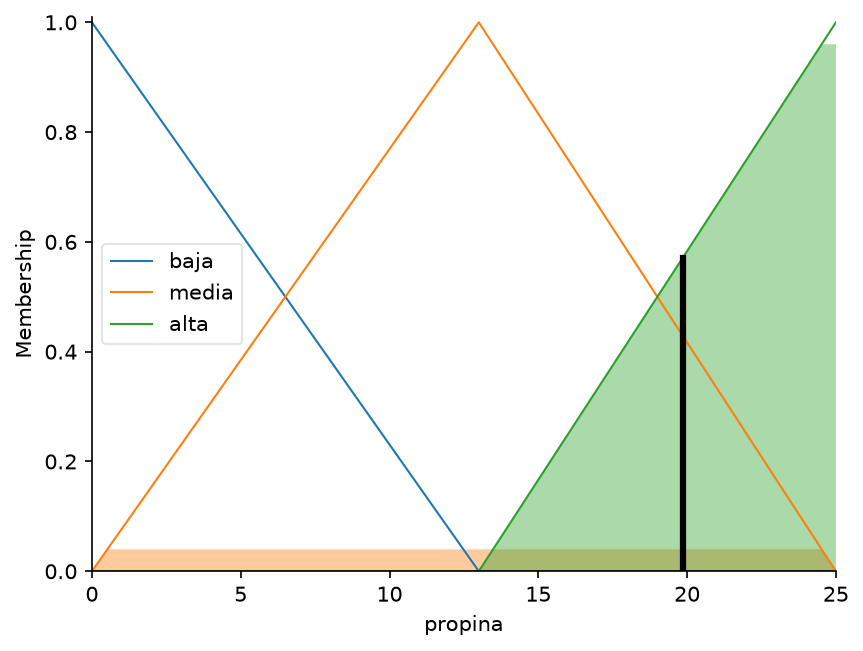

In [3]:
from IPython.display import display, Image
display(Image(filename='resultados/inferencia.png'))